# A0 閱讀

1. K-mean最小化的是每個資料點到自己群中心的距離平方，再全部加總；群中心(cluster center)是該群所有資料點的平均值。
2. 可以指定群數的有kmean、Spectral clustering、Ward hierarchical clustering、Agglomerative clustering、BIRCH、Bisecting K-Means；DBSCAN和MeanShift根據演算法原本的設計方式，群數由資料的密度結構與參數共同決定，無法直接指定為256群。
3. 先計算各群樣本的平均RGB作為調色盤顏色，再將每個像素指派給歐氏距離最近的調色盤顏色，以完成影像量化。
4. 記憶體成本通常隨樣本數呈平方成長，時間成本也會快速增加，依linkage與實作而異；640×427影像共有273,280個像素，直接分群需要大量時間與記憶體，因此應先隨機取樣進行分群，再將全部像素對應到最近的調色盤顏色。
5. 使用隨機取樣的像素fit，可以縮短執行時間並降低記憶體需求，但可能漏掉少見顏色，且結果受抽樣影響。使用全部像素fit能完整考慮原圖的顏色分布，但時間與記憶體成本較高。無論使用哪種方式，最後都將全部像素指派到最近的調色盤顏色。

# A1 用 K-Means 做 256 色影像

原圖 與 量化圖

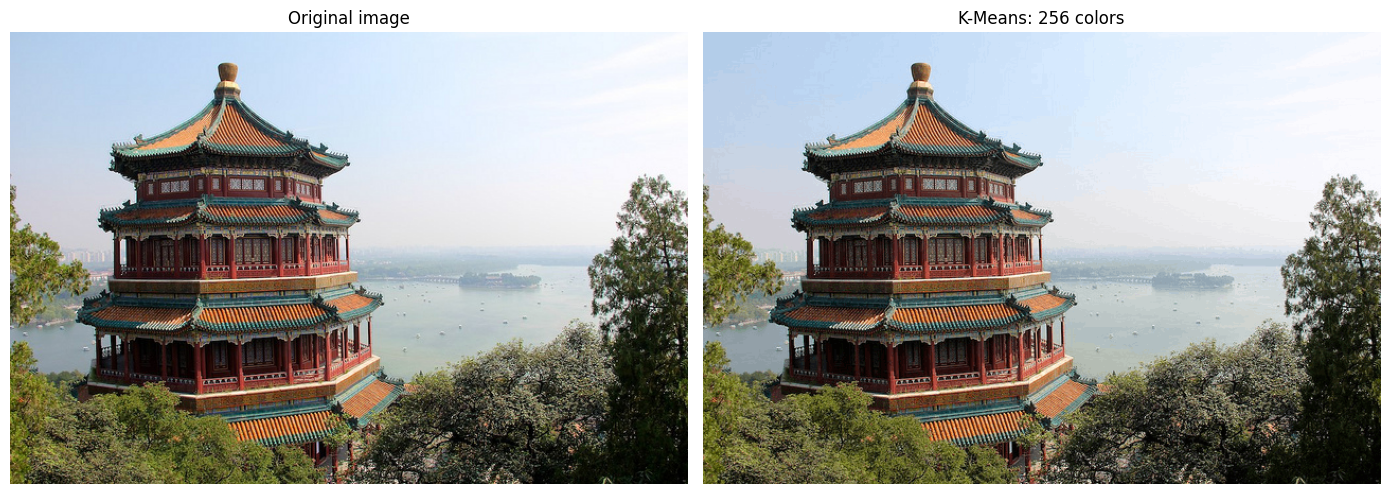

In [19]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_sample_image
from sklearn.cluster import KMeans
from sklearn.metrics import pairwise_distances_argmin

# 1. 載入圖片，將像素值從 [0, 255] 縮放到 [0, 1]
original_image = load_sample_image("china.jpg")
image = original_image.astype(np.float64) / 255.0

height, width, channels = image.shape
pixels = image.reshape(-1, 3)

# 2. 隨機抽取 10,000 個像素，不重複取樣
rng = np.random.default_rng(42)
sample_indices = rng.choice(len(pixels), size=10000, replace=False)
sample_pixels = pixels[sample_indices]

# 3. 用取樣像素訓練 KMeans，取得 256 個代表色
kmeans = KMeans(n_clusters=256, random_state=42, n_init=1)
kmeans.fit(sample_pixels)

palette = kmeans.cluster_centers_

# 4. 將全部像素指派到最近的代表色
labels = pairwise_distances_argmin(pixels, palette)

# 用代表色替換每個像素，並組回原本的圖片形狀
quantized_image = palette[labels].reshape(height, width, channels)

# 5. 原圖與量化結果並排顯示
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].imshow(original_image)
axes[0].set_title("Original image")
axes[0].axis("off")

axes[1].imshow(quantized_image)
axes[1].set_title("K-Means: 256 colors")
axes[1].axis("off")

plt.tight_layout()
plt.show()

局部放大圖 與 16*16色塊格子

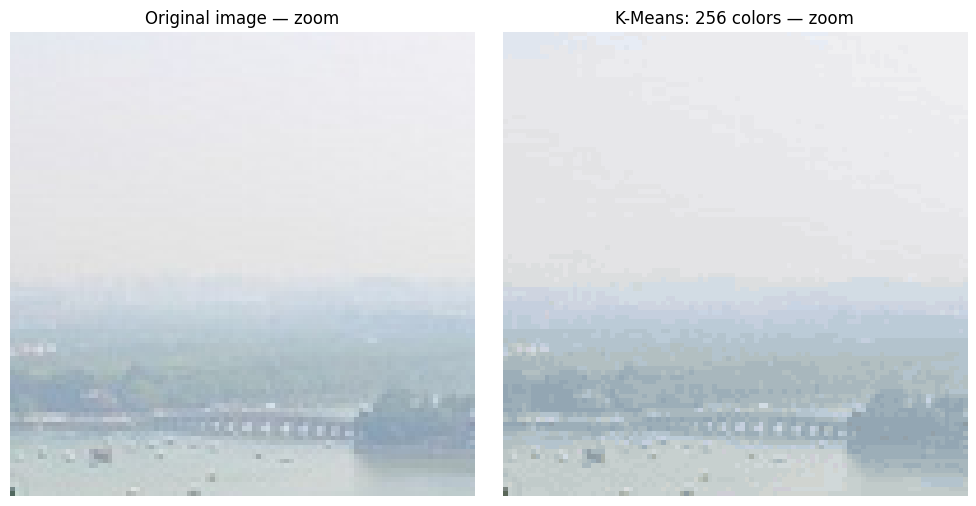

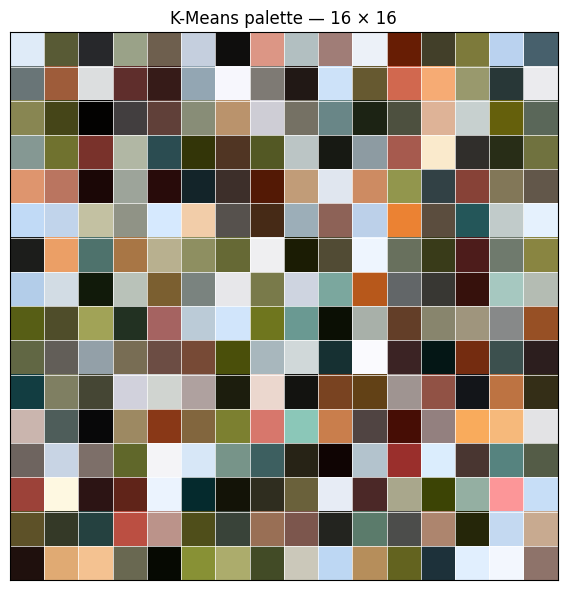

In [20]:
y1, y2 = 150, 250
x1, x2 = 350, 450

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(original_image[y1:y2, x1:x2], interpolation="nearest")
axes[0].set_title("Original image — zoom")
axes[0].axis("off")

axes[1].imshow(quantized_image[y1:y2, x1:x2], interpolation="nearest")
axes[1].set_title("K-Means: 256 colors — zoom")
axes[1].axis("off")

plt.tight_layout()
plt.show()


# 將 256 個代表色排列成 16 × 16 調色盤
palette_grid = palette.reshape(16, 16, 3)

fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(palette_grid, interpolation="nearest")
ax.set_title("K-Means palette — 16 × 16")

# 在色塊邊界畫格線
ax.set_xticks(np.arange(-0.5, 16, 1), minor=True)
ax.set_yticks(np.arange(-0.5, 16, 1), minor=True)
ax.grid(which="minor", color="white", linewidth=0.5)

# 隱藏刻度與刻度標籤，保留格線
ax.tick_params(which="both", bottom=False, left=False, labelbottom=False, labelleft=False)

plt.tight_layout()
plt.show()

# A2 比較分群方法

準備方法 與 比較函式

In [21]:
import pandas as pd

from time import perf_counter
from IPython.display import display
from sklearn.cluster import MiniBatchKMeans, AgglomerativeClustering, BisectingKMeans, Birch

# 沿用 A1 的 image，值域為 [0, 1]
pixels = image.reshape(-1, 3)

# 固定樣本，讓不同方法及兩種 K 使用一致的資料
rng_a2 = np.random.default_rng(42)
sample_indices_a2 = rng_a2.choice(len(pixels), size=10000, replace=False)

sample_10k = pixels[sample_indices_a2]
sample_3k = sample_10k[:3000]

# 隨機調色盤也固定抽樣位置
random_palette_indices = rng_a2.choice(len(pixels), size=256, replace=False)


def uniform_palette(k):
    """建立剛好 k 色的均勻 RGB 調色盤。"""
    levels = {
        256: (8, 8, 4),
        16: (4, 2, 2),
    }
    nr, ng, nb = levels[k]

    grid = np.meshgrid(
        np.linspace(0, 1, nr),
        np.linspace(0, 1, ng),
        np.linspace(0, 1, nb),
        indexing="ij",
    )
    return np.stack(grid, axis=-1).reshape(-1, 3)


def palette_from_labels(samples, labels):
    """沒有群中心屬性時，用每群樣本的平均 RGB 當代表色。"""
    return np.array([
        samples[labels == label].mean(axis=0)
        for label in np.unique(labels)
    ])


def compare_methods(k):
    models = {
        "KMeans": KMeans(n_clusters=k, random_state=42, n_init=1),
        "MiniBatchKMeans": MiniBatchKMeans(n_clusters=k, random_state=42, n_init=1, batch_size=1024),
        "Agglomerative-Ward": AgglomerativeClustering(n_clusters=k, linkage="ward"),
        "Agglomerative-Average": AgglomerativeClustering(n_clusters=k, linkage="average"),
        "BisectingKMeans": BisectingKMeans(n_clusters=k, random_state=42, n_init=1),
        "Birch": Birch(n_clusters=k, threshold=0.01),
    }

    rows = []
    results = {}

    method_names = list(models) + ["Uniform palette", "Random palette"]

    for name in method_names:
        start = perf_counter()

        if name == "Uniform palette":
            current_palette = uniform_palette(k)
            n_samples = 0

        elif name == "Random palette":
            current_palette = pixels[random_palette_indices[:k]]
            n_samples = k

        else:
            samples = (
                sample_3k
                if name.startswith("Agglomerative")
                else sample_10k
            )
            n_samples = len(samples)

            model = models[name]
            model.fit(samples)

            if hasattr(model, "cluster_centers_"):
                current_palette = model.cluster_centers_
            else:
                # Agglomerative 與 Birch：
                # 以各群訓練樣本的平均 RGB 作為代表色
                current_palette = palette_from_labels(samples, model.labels_)

        # 所有方法統一用最近的調色盤顏色指派全部像素
        labels = pairwise_distances_argmin(pixels, current_palette)
        reconstructed = current_palette[labels].reshape(image.shape)

        elapsed = perf_counter() - start

        # 計時結束後才計算評估指標
        mse = np.mean((image - reconstructed) ** 2)
        psnr = np.inf if mse == 0 else -10 * np.log10(mse)

        # 計算重建圖真正出現的不同 RGB 數量
        used_colors = len(np.unique(current_palette[np.unique(labels)], axis=0))

        rows.append({
            "方法": name,
            "使用的樣本數": n_samples,
            "執行時間（秒）": elapsed,
            "MSE": mse,
            "PSNR（dB）": psnr,
            "實際使用顏色數": used_colors,
        })

        results[name] = {
            "image": reconstructed,
            "palette": current_palette,
        }

    return pd.DataFrame(rows), results

執行兩種K 顯示表格

In [22]:
tables_a2 = {}
results_a2 = {}

for k in [256, 16]:
    table, results = compare_methods(k)

    tables_a2[k] = table
    results_a2[k] = results

    print(f"K = {k}")
    display(
        table.style.format({
            "執行時間（秒）": "{:.3f}",
            "MSE": "{:.6f}",
            "PSNR（dB）": "{:.2f}",
        })
    )

K = 256


,方法,使用的樣本數,執行時間（秒）,MSE,PSNR（dB）,實際使用顏色數
0,KMeans,10000,0.198,0.000237,36.24,256
1,MiniBatchKMeans,10000,0.147,0.000259,35.88,256
2,Agglomerative-Ward,3000,0.244,0.000257,35.89,256
3,Agglomerative-Average,3000,0.256,0.000347,34.60,256
4,BisectingKMeans,10000,0.618,0.000254,35.94,256
5,Birch,10000,0.543,0.000279,35.54,256
6,Uniform palette,0,0.071,0.003608,24.43,96
7,Random palette,256,0.066,0.000490,33.10,243


K = 16


,方法,使用的樣本數,執行時間（秒）,MSE,PSNR（dB）,實際使用顏色數
0,KMeans,10000,0.032,0.001795,27.46,16
1,MiniBatchKMeans,10000,0.032,0.001787,27.48,16
2,Agglomerative-Ward,3000,0.188,0.001845,27.34,16
3,Agglomerative-Average,3000,0.193,0.003572,24.47,16
4,BisectingKMeans,10000,0.035,0.001861,27.30,16
5,Birch,10000,0.500,0.002941,25.32,16
6,Uniform palette,0,0.019,0.035442,14.50,13
7,Random palette,16,0.020,0.003219,24.92,16


局部放大比較圖

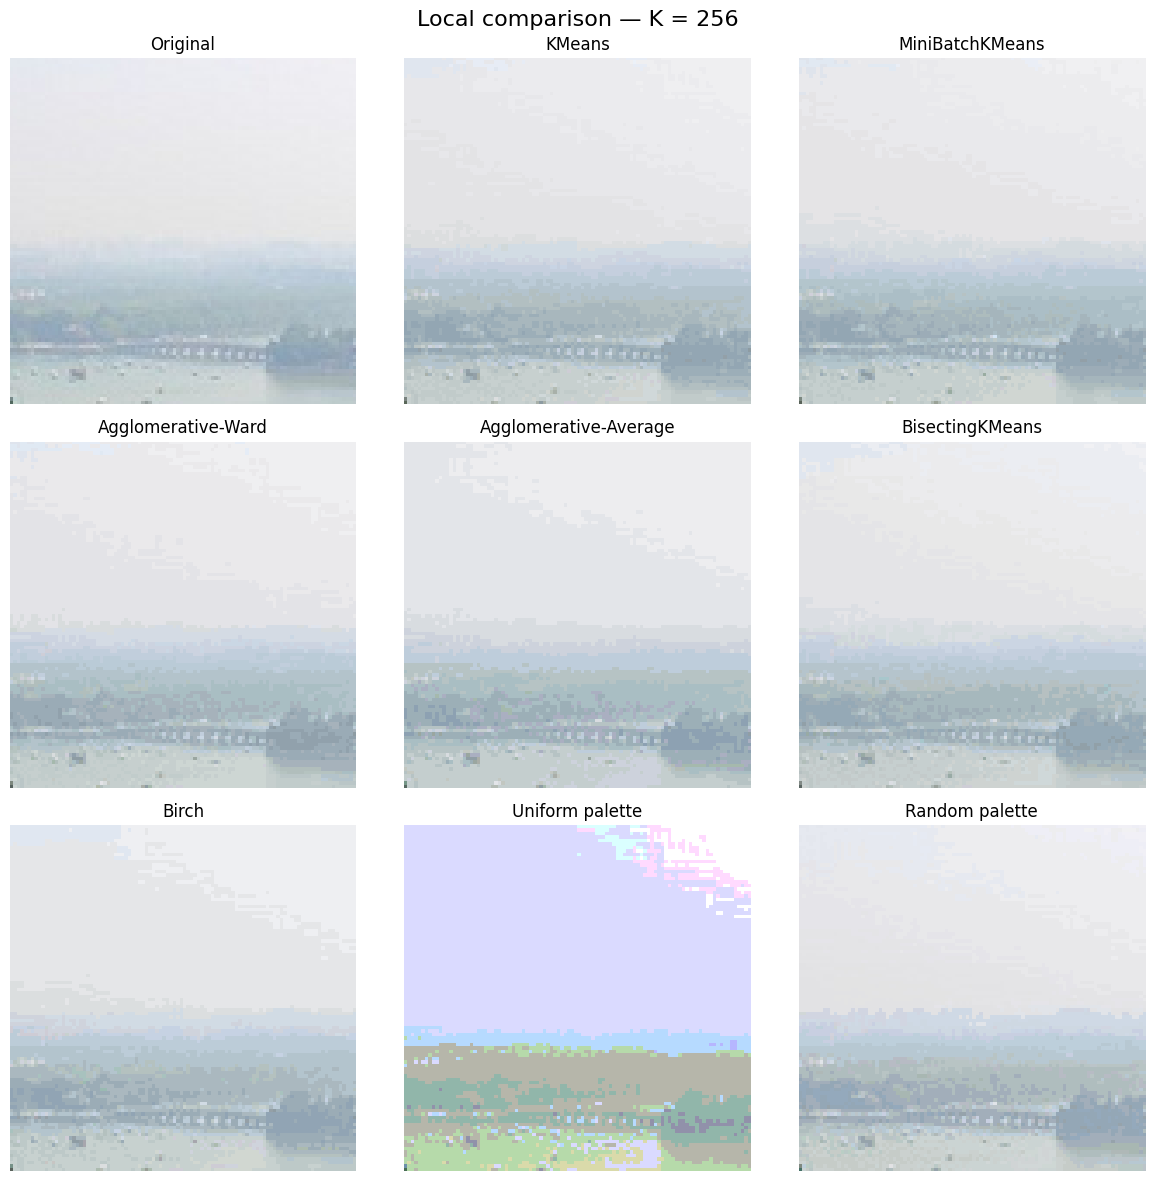

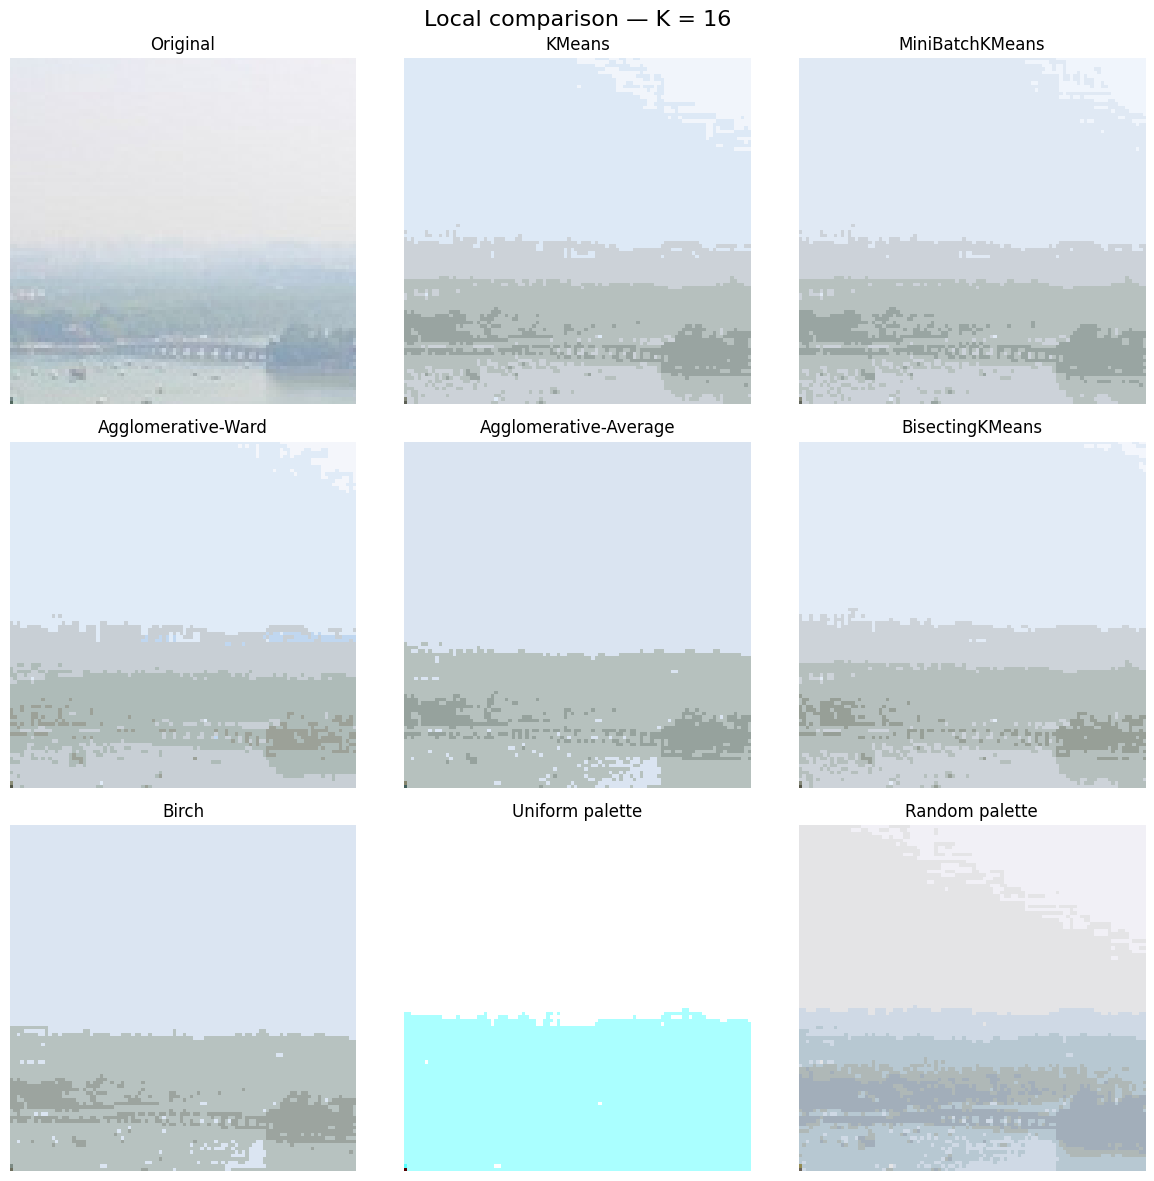

In [23]:
for k in [256, 16]:
    # 原圖 + 8 組方法，共 9 張
    fig, axes = plt.subplots(3, 3, figsize=(12, 12))

    panels = [("Original", image)] + [
        (name, result["image"])
        for name, result in results_a2[k].items()
    ]

    for ax, (name, img) in zip(axes.ravel(), panels):
        ax.imshow(img[y1:y2, x1:x2], interpolation="nearest")
        ax.set_title(name)
        ax.axis("off")

    fig.suptitle(f"Local comparison — K = {k}", fontsize=16)
    plt.tight_layout()
    plt.show()

差異圖

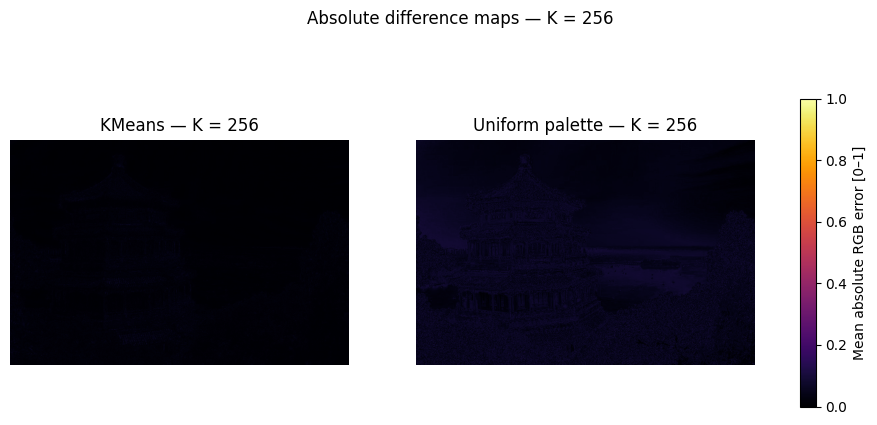

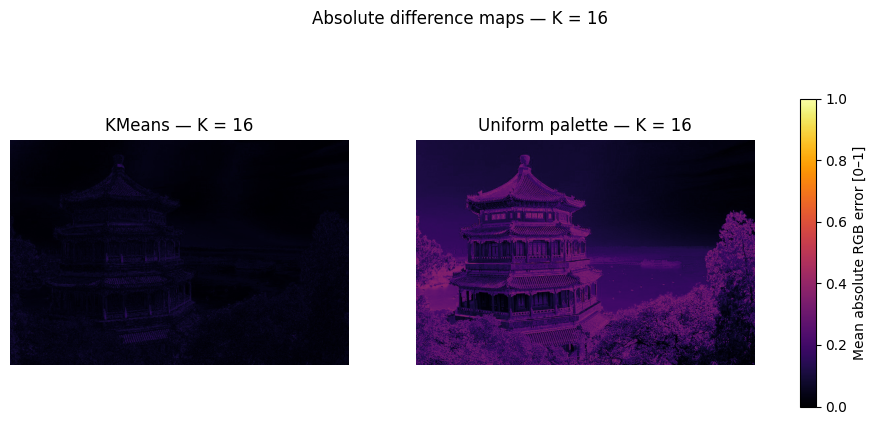

In [24]:
methods_to_compare = ["KMeans", "Uniform palette"]

for k in [256, 16]:
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    for ax, name in zip(axes, methods_to_compare):
        reconstructed = results_a2[k][name]["image"]

        # 題目指定的逐通道絕對差異
        difference = np.abs(image - reconstructed)

        # 將三個通道的絕對差取平均，方便用單一色階呈現
        error_map = difference.mean(axis=2)

        plot = ax.imshow(error_map, cmap="inferno", vmin=0, vmax=1)
        ax.set_title(f"{name} — K = {k}")
        ax.axis("off")

    fig.colorbar(plot, ax=axes.tolist(), label="Mean absolute RGB error [0–1]", shrink=0.8)
    fig.suptitle(f"Absolute difference maps — K = {k}")
    plt.show()

# A3 視覺化分群的效果

兩張 3D RGB 散佈圖

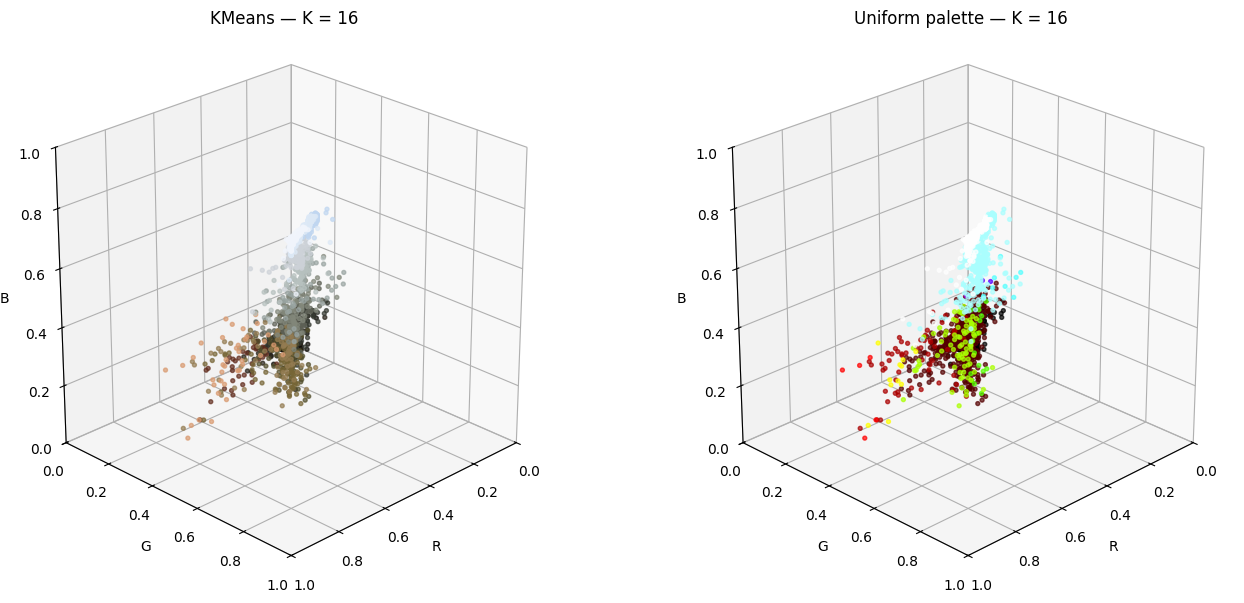

In [25]:
# 隨機抽取同一組 2,000 個像素來畫圖
rng_a3 = np.random.default_rng(42)
plot_indices = rng_a3.choice(len(pixels), size=2000, replace=False)
plot_pixels = pixels[plot_indices]

methods_a3 = ["KMeans", "Uniform palette"]

fig = plt.figure(figsize=(14, 6))

for i, name in enumerate(methods_a3, start=1):
    current_palette = results_a2[16][name]["palette"]

    # 找出這些像素對應的代表色
    labels = pairwise_distances_argmin(plot_pixels, current_palette)
    assigned_colors = current_palette[labels]

    ax = fig.add_subplot(1, 2, i, projection="3d")
    ax.scatter(
        plot_pixels[:, 0],
        plot_pixels[:, 1],
        plot_pixels[:, 2],
        c=assigned_colors,
        s=8,
        alpha=0.7,
        depthshade=False,
    )

    ax.set_title(f"{name} — K = 16")
    ax.set_xlabel("R")
    ax.set_ylabel("G")
    ax.set_zlabel("B")

    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_zlim(0, 1)
    ax.set_box_aspect((1, 1, 1))
    ax.view_init(elev=25, azim=45)

plt.tight_layout()
plt.show()

誤差對K曲線

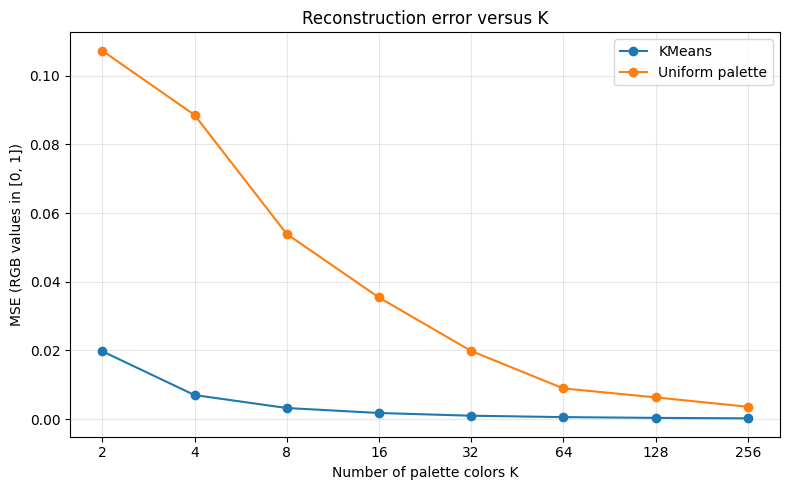

In [26]:
uniform_levels = {
    2:   (2, 1, 1),
    4:   (2, 2, 1),
    8:   (2, 2, 2),
    16:  (4, 2, 2),
    32:  (4, 4, 2),
    64:  (4, 4, 4),
    128: (8, 4, 4),
    256: (8, 8, 4),
}


def make_uniform_palette(k):
    # 只有一階的通道使用中間值 0.5
    axes = [
        np.linspace(0, 1, n) if n > 1 else np.array([0.5])
        for n in uniform_levels[k]
    ]

    grid = np.meshgrid(*axes, indexing="ij")
    return np.stack(grid, axis=-1).reshape(-1, 3)


k_values = [2, 4, 8, 16, 32, 64, 128, 256]
curve_rows = []

for k in k_values:
    # K = 16、256 直接沿用 A2 的調色盤
    if k in results_a2:
        palettes = {
            name: results_a2[k][name]["palette"]
            for name in methods_a3
        }
    else:
        model = KMeans(n_clusters=k, random_state=42, n_init=1)
        model.fit(sample_10k)

        palettes = {
            "KMeans": model.cluster_centers_,
            "Uniform palette": make_uniform_palette(k),
        }

    for name, current_palette in palettes.items():
        # 使用全部像素計算重建誤差
        labels = pairwise_distances_argmin(pixels, current_palette)
        mse = np.mean((pixels - current_palette[labels]) ** 2)

        curve_rows.append({
            "方法": name,
            "K": k,
            "MSE": mse,
        })

curve_table = pd.DataFrame(curve_rows)

fig, ax = plt.subplots(figsize=(8, 5))

for name in methods_a3:
    subset = curve_table[curve_table["方法"] == name]
    ax.plot(subset["K"], subset["MSE"], marker="o", label=name)

ax.set_xscale("log", base=2)
ax.set_xticks(k_values)
ax.set_xticklabels(k_values)
ax.set_xlabel("Number of palette colors K")
ax.set_ylabel("MSE (RGB values in [0, 1])")
ax.set_title("Reconstruction error versus K")
ax.grid(True, alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

### 討論

KMeans的代表色會配合原圖的顏色分布；Uniform palette使用固定代表色，因此部分像素會被指派到與原色差距較大的顏色。<br>
兩張散佈圖的位置相同，差別在於指派後的代表色。

# A4 討論

表現好：KMeans，因為執行時間短，K＝256時重建品質最佳，K＝16時也與最佳結果接近，取樣訓練可控制記憶體需求。<br>
表現不好：Uniform palette，因為固定的代表色無法配合原圖的顏色分布，量化後的顏色差異明顯。

# B1 實作 Floyd–Steinberg dithering

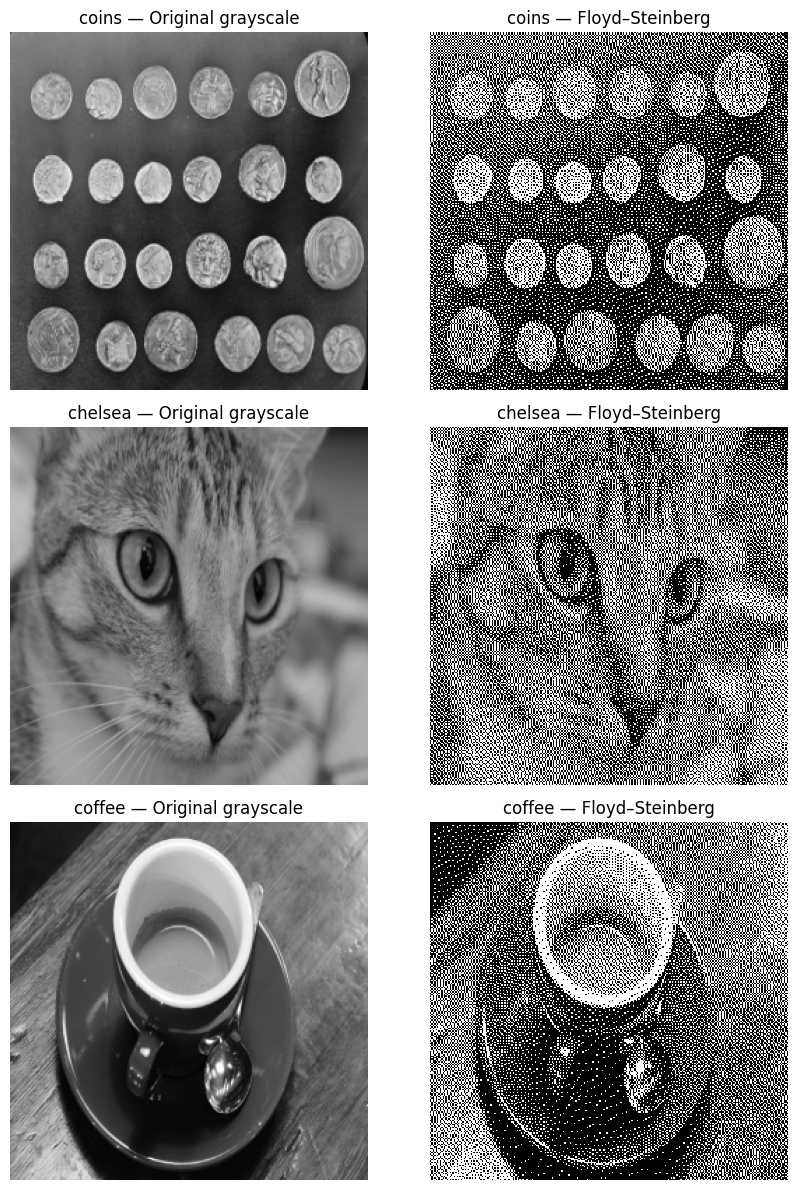

In [27]:
from skimage import data, color
from skimage.transform import resize
from skimage.util import img_as_float


def fs_dither(img):
    # 複製影像，避免修改輸入的原圖
    result = np.array(img, dtype=np.float64, copy=True)
    height, width = result.shape

    # 由上到下、由左到右處理
    for y in range(height):
        for x in range(width):
            old_value = result[y, x]
            new_value = 1.0 if old_value >= 0.5 else 0.0

            result[y, x] = new_value
            error = old_value - new_value

            # 右方
            if x + 1 < width:
                result[y, x + 1] += error * 7 / 16

            if y + 1 < height:
                # 左下
                if x > 0:
                    result[y + 1, x - 1] += error * 3 / 16

                # 下方
                result[y + 1, x] += error * 5 / 16

                # 右下
                if x + 1 < width:
                    result[y + 1, x + 1] += error * 1 / 16

    return result


def prepare_gray(img):
    """轉成 [0, 1] 灰階影像，並縮放到 256 × 256。"""
    img = img_as_float(img)

    # 彩色圖才需要轉灰階
    if img.ndim == 3:
        img = color.rgb2gray(img)

    return resize(img, (256, 256), anti_aliasing=True, preserve_range=True)


# 使用三張訓練影像示範
demo_images = {
    "coins": prepare_gray(data.coins()),
    "chelsea": prepare_gray(data.chelsea()),
    "coffee": prepare_gray(data.coffee()),
}

fig, axes = plt.subplots(3, 2, figsize=(9, 12))

for row, (name, gray) in enumerate(demo_images.items()):
    dithered = fs_dither(gray)

    axes[row, 0].imshow(gray, cmap="gray", vmin=0, vmax=1)
    axes[row, 0].set_title(f"{name} — Original grayscale")
    axes[row, 0].axis("off")

    axes[row, 1].imshow(dithered, cmap="gray", vmin=0, vmax=1, interpolation="nearest")
    axes[row, 1].set_title(f"{name} — Floyd–Steinberg")
    axes[row, 1].axis("off")

plt.tight_layout()
plt.show()

# B2 資料集

In [28]:
train_loaders = {
    "coins": data.coins,
    "moon": data.moon,
    "chelsea": data.chelsea,
    "coffee": data.coffee,
    "rocket": data.rocket,
    "brick": data.brick,
    "grass": data.grass,
    "gravel": data.gravel,
    "page": data.page,
}

test_loaders = {
    "camera": data.camera,
    "astronaut": data.astronaut,
}

def build_dataset(loaders):
    dataset = {}

    for name, loader in loaders.items():
        # 轉灰階、縮放至 256 × 256，值域為 [0, 1]
        gray = prepare_gray(loader())

        # 產生黑白 dithering 影像
        dithered = fs_dither(gray)

        dataset[name] = {
            "gray": gray,
            "dithered": dithered,
        }

    return dataset


train_images = build_dataset(train_loaders)
test_images = build_dataset(test_loaders)

# 顯示資料集資訊
dataset_rows = []

for split, dataset in [
    ("Train", train_images),
    ("Test", test_images),
]:
    for name, item in dataset.items():
        dataset_rows.append({
            "資料集": split,
            "影像": name,
            "尺寸": str(item["gray"].shape),
            "像素數": item["gray"].size,
            "灰階最小值": item["gray"].min(),
            "灰階最大值": item["gray"].max(),
            "Dithering 值": str(np.unique(item["dithered"]).tolist()),
        })

display(pd.DataFrame(dataset_rows))

print(
    "訓練像素總數：",
    sum(item["gray"].size for item in train_images.values())
)
print(
    "測試像素總數：",
    sum(item["gray"].size for item in test_images.values())
)

,資料集,影像,尺寸,像素數,灰階最小值,灰階最大值,Dithering 值
0,Train,coins,"(256, 256)",65536,0.013984,0.940349,"[0.0, 1.0]"
1,Train,moon,"(256, 256)",65536,0.000056,0.984459,"[0.0, 1.0]"
2,Train,chelsea,"(256, 256)",65536,0.015857,0.753375,"[0.0, 1.0]"
3,Train,coffee,"(256, 256)",65536,0.014156,0.995610,"[0.0, 1.0]"
4,Train,rocket,"(256, 256)",65536,0.011100,0.994496,"[0.0, 1.0]"
5,Train,brick,"(256, 256)",65536,0.283752,0.782689,"[0.0, 1.0]"
6,Train,grass,"(256, 256)",65536,0.053076,0.852458,"[0.0, 1.0]"
7,Train,gravel,"(256, 256)",65536,0.019020,0.900004,"[0.0, 1.0]"
8,Train,page,"(256, 256)",65536,0.044018,0.995620,"[0.0, 1.0]"
9,Test,camera,"(256, 256)",65536,0.008466,0.999493,"[0.0, 1.0]"


訓練像素總數： 589824
測試像素總數： 131072


# B3 特徵與目標

固定取樣位置、建立特徵函式 (使用7×7與11×11區塊，所有模型共用同一組隨機抽取的60,000個訓練像素，兩張測試影像皆使用全部像素評估)

In [29]:
from numpy.lib.stride_tricks import sliding_window_view

patch_sizes = [7, 11]
n_train_samples = 60000

train_names = list(train_images)

# 將九張訓練影像的目標灰階值依序串接
all_targets = np.concatenate([
    train_images[name]["gray"].ravel()
    for name in train_names
])

# 隨機抽取 60,000 個不重複的像素位置
rng_b3 = np.random.default_rng(42)
train_indices = rng_b3.choice(len(all_targets), size=n_train_samples, replace=False)

# 兩種區塊大小共用相同的目標
y_train = all_targets[train_indices].astype(np.float32)


def patch_view(dithered, k):
    """回傳 (高度, 寬度, k, k) 的區塊視圖。"""
    padded = np.pad(dithered, pad_width=k // 2, mode="reflect")
    return sliding_window_view(padded, (k, k))


def make_train_features(k):
    """只擷取抽中的訓練區塊，避免建立全部訓練特徵。"""
    X = np.empty((n_train_samples, k * k), dtype=np.float32)

    offset = 0

    for name in train_names:
        dithered = train_images[name]["dithered"]
        height, width = dithered.shape
        n_pixels = height * width

        # 找出抽樣位置中，屬於這張影像的項目
        selected_rows = np.flatnonzero((train_indices >= offset) & (train_indices < offset + n_pixels))

        local_indices = train_indices[selected_rows] - offset
        ys, xs = np.unravel_index(local_indices, (height, width))

        windows = patch_view(dithered, k)

        X[selected_rows] = windows[ys, xs].reshape(-1, k * k)

        offset += n_pixels

    return X


def make_test_features(dithered, k):
    """建立一張測試影像全部像素的區塊特徵。"""
    windows = patch_view(dithered, k)

    return windows.reshape(-1, k * k).astype(np.float32)

建立兩種大小的訓練 與 測試資料

In [30]:
X_train_by_k = {
    k: make_train_features(k)
    for k in patch_sizes
}

X_test_by_k = {
    k: {
        name: make_test_features(item["dithered"], k)
        for name, item in test_images.items()
    }
    for k in patch_sizes
}

y_test = {
    name: item["gray"].ravel().astype(np.float32)
    for name, item in test_images.items()
}

# 顯示資料形狀
feature_rows = []

for k in patch_sizes:
    feature_rows.append({
        "資料集": "Train",
        "影像": "All training images",
        "區塊大小": f"{k}×{k}",
        "X 形狀": str(X_train_by_k[k].shape),
        "y 形狀": str(y_train.shape),
    })

    for name in test_images:
        feature_rows.append({
            "資料集": "Test",
            "影像": name,
            "區塊大小": f"{k}×{k}",
            "X 形狀": str(X_test_by_k[k][name].shape),
            "y 形狀": str(y_test[name].shape),
        })

display(pd.DataFrame(feature_rows))

,資料集,影像,區塊大小,X 形狀,y 形狀
0,Train,All training images,7×7,"(60000, 49)","(60000,)"
1,Test,camera,7×7,"(65536, 49)","(65536,)"
2,Test,astronaut,7×7,"(65536, 49)","(65536,)"
3,Train,All training images,11×11,"(60000, 121)","(60000,)"
4,Test,camera,11×11,"(65536, 121)","(65536,)"
5,Test,astronaut,11×11,"(65536, 121)","(65536,)"


# B4 Baseline

In [31]:
from scipy.ndimage import gaussian_filter
from skimage.metrics import peak_signal_noise_ratio

# 只在訓練影像上選擇 sigma
sigma_candidates = [0.5, 0.75, 1.0, 1.25, 1.5, 2.0, 2.5, 3.0]
sigma_rows = []

for sigma in sigma_candidates:
    image_mses = []

    for item in train_images.values():
        restored = gaussian_filter(item["dithered"], sigma=sigma, mode="reflect")

        image_mses.append(np.mean((item["gray"] - restored) ** 2))

    sigma_rows.append({
        "sigma（像素）": sigma,
        "訓練平均 MSE": np.mean(image_mses),
    })

sigma_table = pd.DataFrame(sigma_rows)

best_row = sigma_table["訓練平均 MSE"].idxmin()
best_sigma = float(sigma_table.loc[best_row, "sigma（像素）"])

display(
    sigma_table.style.format({
        "sigma（像素）": "{:.2f}",
        "訓練平均 MSE": "{:.6f}",
    })
)

print(f"選出的最佳 sigma：{best_sigma}")


# 使用選定的 sigma，在測試影像全部像素上評估
blur_results = {}
baseline_rows = []

for name, item in test_images.items():
    start = perf_counter()

    restored = gaussian_filter(item["dithered"], sigma=best_sigma, mode="reflect")

    prediction_time = perf_counter() - start

    psnr = peak_signal_noise_ratio(item["gray"], restored, data_range=1.0)

    # 保留結果，供 B5 的表格與繪圖使用
    blur_results[name] = {
        "image": restored,
        "psnr": psnr,
        "prediction_time": prediction_time,
    }

    baseline_rows.append({
        "測試影像": name,
        "sigma（像素）": best_sigma,
        "PSNR（dB）": psnr,
    })

baseline_table = pd.DataFrame(baseline_rows)

display(
    baseline_table.style.format({
        "sigma（像素）": "{:.2f}",
        "PSNR（dB）": "{:.2f}",
    })
)

,sigma（像素）,訓練平均 MSE
0,0.50,0.050637
1,0.75,0.005023
2,1.00,0.002448
3,1.25,0.002721
4,1.50,0.003286
5,2.00,0.004368
6,2.50,0.005257
7,3.00,0.005991


選出的最佳 sigma：1.0


,測試影像,sigma（像素）,PSNR（dB）
0,camera,1.00,27.12
1,astronaut,1.00,26.62


# B5 模型

訓練、預測及結果表格

In [32]:
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.neural_network import MLPRegressor
from threadpoolctl import threadpool_limits


def create_models():
    # 使用較精簡的設定，控制 CPU 執行時間
    return {
        "Ridge": Ridge(alpha=1.0),

        "RandomForest": RandomForestRegressor(n_estimators=24, max_depth=12, min_samples_leaf=5, max_features=0.5,
                                              max_samples=0.5, n_jobs=2, random_state=42),

        "HistGradientBoosting": HistGradientBoostingRegressor(max_iter=60, max_leaf_nodes=15, learning_rate=0.1,
                                                              early_stopping=True, random_state=42),

        "MLP": MLPRegressor(hidden_layer_sizes=(32,),max_iter=100, batch_size=512, early_stopping=True,
                            n_iter_no_change=8, random_state=42),
    }


trained_models = {}
model_results = {}
model_rows = []

# Baseline 沒有模型 fit；sigma 搜尋時間不列入訓練時間
model_rows.append({
    "模型": "Gaussian blur",
    "區塊大小": "—",
    "訓練時間（秒）": 0.0,
    "預測時間（秒）": sum(
        result["prediction_time"]
        for result in blur_results.values()
    ),
    "camera PSNR（dB）": blur_results["camera"]["psnr"],
    "astronaut PSNR（dB）": blur_results["astronaut"]["psnr"],
})

# 限制底層運算執行緒，避免大量執行緒反而拖慢小型運算
with threadpool_limits(limits=2):
    for k in patch_sizes:
        for name, model in create_models().items():
            print(f"Training {name}, k = {k} ...", flush=True)

            start = perf_counter()
            model.fit(X_train_by_k[k], y_train)
            train_time = perf_counter() - start

            predictions = {}
            scores = {}
            prediction_time = 0.0

            for image_name in test_images:
                start = perf_counter()

                predicted = model.predict(X_test_by_k[k][image_name])
                predicted = np.clip(predicted, 0, 1)

                prediction_time += perf_counter() - start

                restored = predicted.reshape(test_images[image_name]["gray"].shape)

                predictions[image_name] = restored
                scores[image_name] = peak_signal_noise_ratio(test_images[image_name]["gray"], restored, data_range=1.0)

            key = (name, k)
            trained_models[key] = model
            model_results[key] = {
                "images": predictions,
                "scores": scores,
            }

            model_rows.append({
                "模型": name,
                "區塊大小": f"{k}×{k}",
                "訓練時間（秒）": train_time,
                "預測時間（秒）": prediction_time,
                "camera PSNR（dB）": scores["camera"],
                "astronaut PSNR（dB）": scores["astronaut"],
            })

b5_table = pd.DataFrame(model_rows)

display(
    b5_table.style.format({
        "訓練時間（秒）": "{:.3f}",
        "預測時間（秒）": "{:.3f}",
        "camera PSNR（dB）": "{:.2f}",
        "astronaut PSNR（dB）": "{:.2f}",
    })
)

Training Ridge, k = 7 ...
Training RandomForest, k = 7 ...
Training HistGradientBoosting, k = 7 ...
Training MLP, k = 7 ...
Training Ridge, k = 11 ...
Training RandomForest, k = 11 ...
Training HistGradientBoosting, k = 11 ...
Training MLP, k = 11 ...


,模型,區塊大小,訓練時間（秒）,預測時間（秒）,camera PSNR（dB）,astronaut PSNR（dB）
0,Gaussian blur,—,0.000,0.002,27.12,26.62
1,Ridge,7×7,0.018,0.006,28.12,27.67
2,RandomForest,7×7,1.210,0.228,28.18,26.37
3,HistGradientBoosting,7×7,0.845,0.635,28.59,27.21
4,MLP,7×7,3.777,0.026,28.06,27.37
5,Ridge,11×11,0.056,0.016,28.16,27.72
6,RandomForest,11×11,2.830,0.231,28.03,26.25
7,HistGradientBoosting,11×11,1.819,0.929,28.58,27.22
8,MLP,11×11,5.197,0.032,28.05,27.55


找出最佳兩種模型，顯示完整圖與相同區域的局部放大

展示的最佳兩種模型： [('Ridge', 11), ('HistGradientBoosting', 11)]


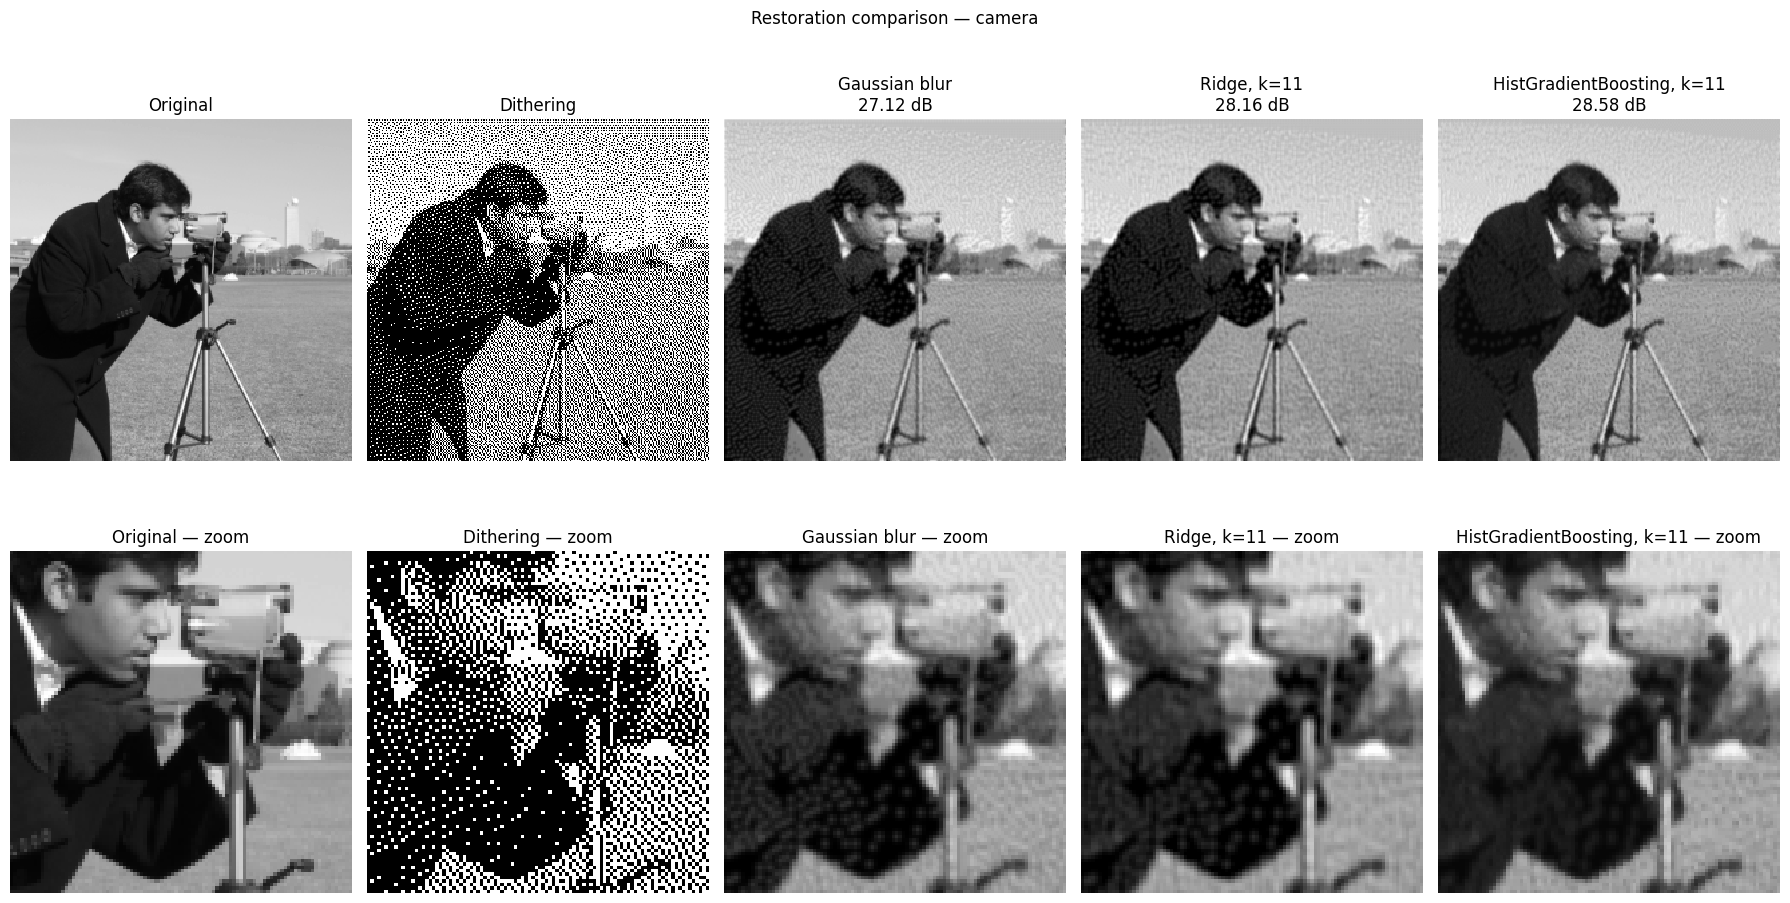

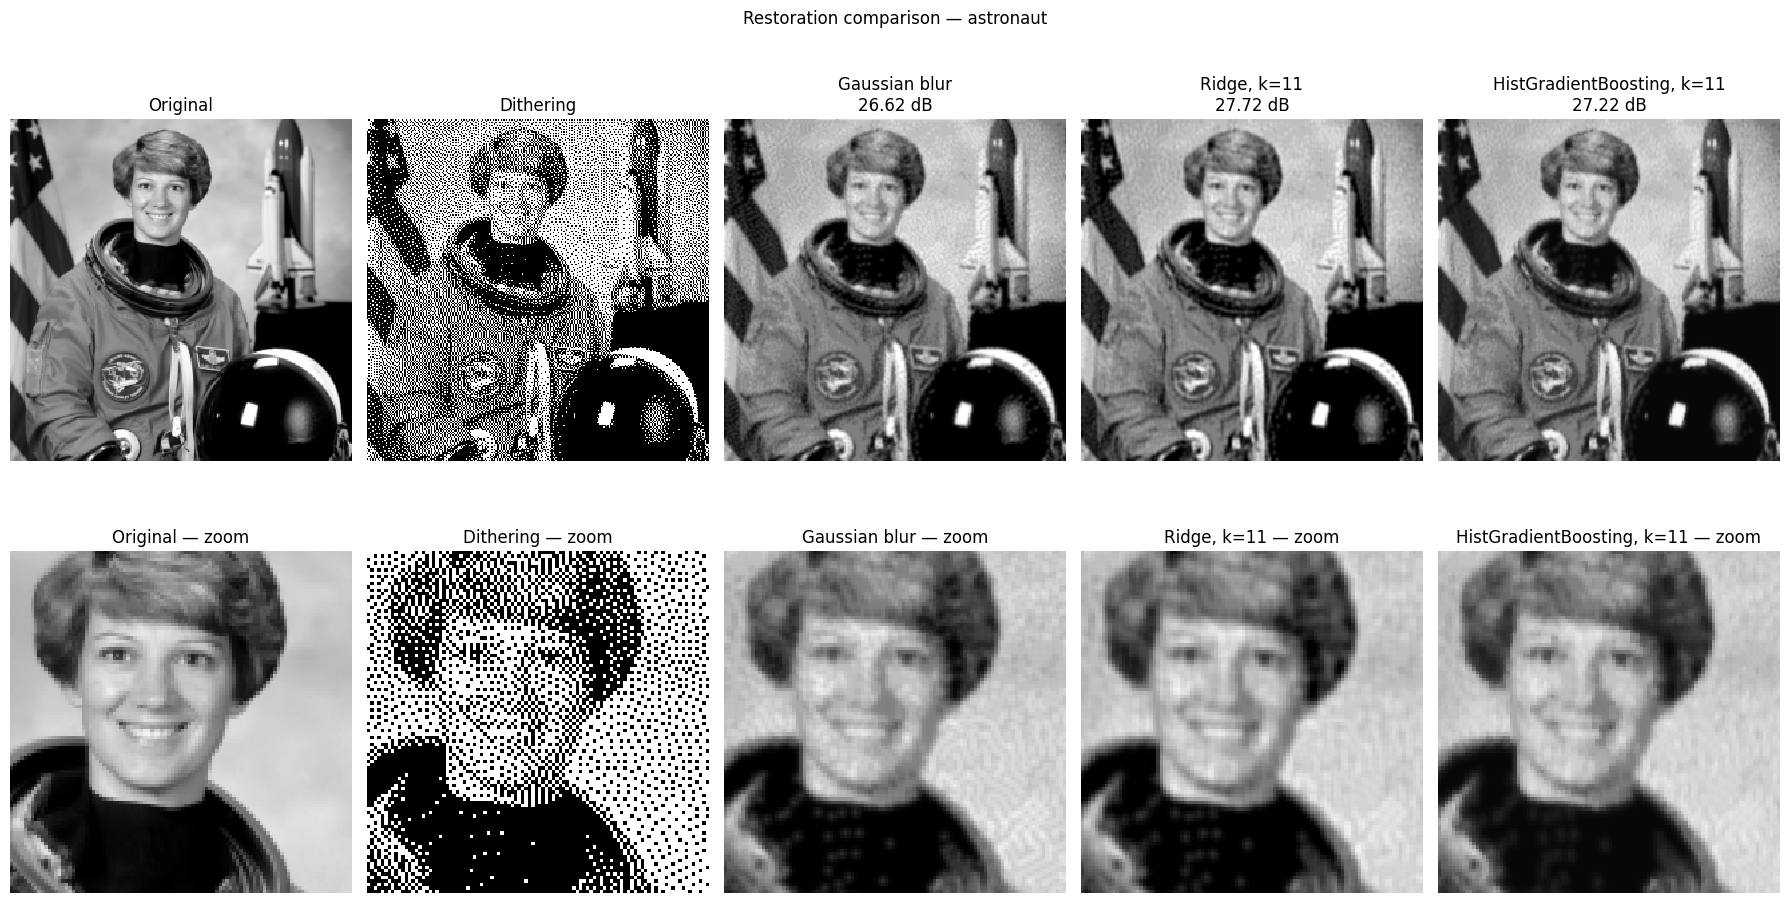

In [36]:
# 每種模型挑選平均測試 PSNR 較高的區塊大小
best_per_model = {}

for key, result in model_results.items():
    name, k = key
    mean_psnr = np.mean(list(result["scores"].values()))

    if name not in best_per_model or mean_psnr > best_per_model[name][1]:
        best_per_model[name] = (key, mean_psnr)

best_two = [
    entry[0]
    for entry in sorted(best_per_model.values(), key=lambda entry: entry[1], reverse=True)[:2]
]

print("展示的最佳兩種模型：", best_two)

# 每張影像中，所有方法使用相同裁切範圍
crop_regions = {
    "camera": (60, 160, 80, 180),
    "astronaut": (20, 120, 70, 170),
}

for image_name, item in test_images.items():
    panels = [
        ("Original", item["gray"]),
        ("Dithering", item["dithered"]),
        (
            f"Gaussian blur\n"
            f"{blur_results[image_name]['psnr']:.2f} dB",
            blur_results[image_name]["image"],
        ),
    ]

    for key in best_two:
        name, k = key
        result = model_results[key]

        panels.append((
            f"{name}, k={k}\n"
            f"{result['scores'][image_name]:.2f} dB",
            result["images"][image_name],
        ))

    fig, axes = plt.subplots(2, 5, figsize=(18, 10))
    cy1, cy2, cx1, cx2 = crop_regions[image_name]

    for col, (title, img) in enumerate(panels):
        axes[0, col].imshow(img, cmap="gray", vmin=0, vmax=1, interpolation="nearest")
        axes[0, col].set_title(title)
        axes[0, col].axis("off")

        axes[1, col].imshow(img[cy1:cy2, cx1:cx2], cmap="gray", vmin=0, vmax=1, interpolation="nearest")
        axes[1, col].set_title(f"{title.splitlines()[0]} — zoom")
        axes[1, col].axis("off")

    fig.suptitle(f"Restoration comparison — {image_name}")
    plt.tight_layout()
    plt.show()

將Ridge係數畫成濾波器，與高斯濾波器比較

Ridge k=7: 係數總和=1.0019, 截距=-0.0006
Ridge k=11: 係數總和=0.9991, 截距=0.0006


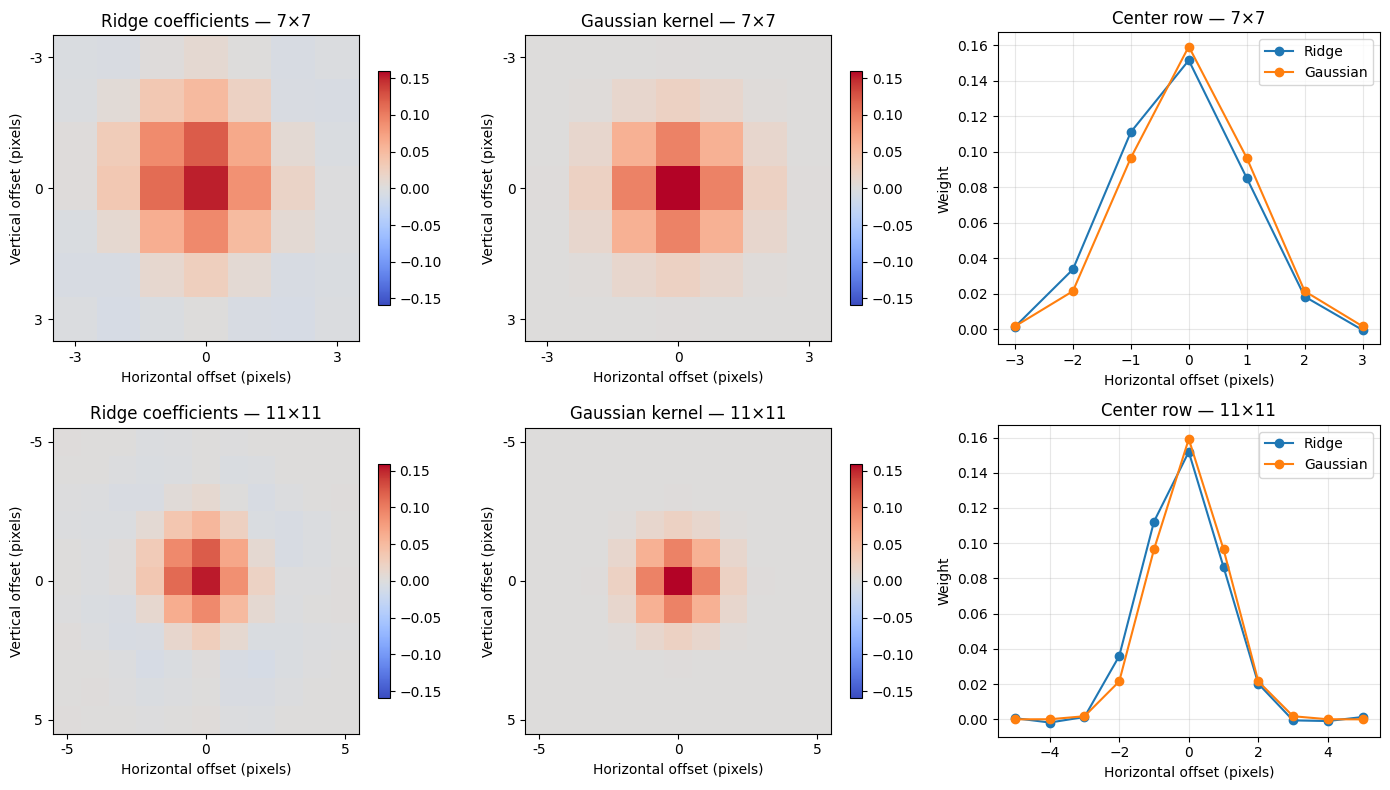

In [34]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8))

for row, k in enumerate(patch_sizes):
    ridge = trained_models[("Ridge", k)]
    weights = ridge.coef_.reshape(k, k)

    # 建立相同大小的高斯濾波器，供視覺比較
    coords = np.arange(k) - k // 2
    xx, yy = np.meshgrid(coords, coords)

    gaussian_kernel = np.exp(-(xx**2 + yy**2) / (2 * best_sigma**2))
    gaussian_kernel /= gaussian_kernel.sum()

    # Ridge 與 Gaussian 使用相同色階
    limit = max(np.abs(weights).max(), np.abs(gaussian_kernel).max())

    for col, (title, kernel) in enumerate([("Ridge coefficients", weights), ("Gaussian kernel", gaussian_kernel)]):
        ax = axes[row, col]
        plot = ax.imshow(kernel, cmap="coolwarm", vmin=-limit, vmax=limit)
        ax.set_title(f"{title} — {k}×{k}")
        ax.set_xlabel("Horizontal offset (pixels)")
        ax.set_ylabel("Vertical offset (pixels)")

        ticks = [0, k // 2, k - 1]
        labels = [-k // 2 + 1, 0, k // 2]
        ax.set_xticks(ticks, labels)
        ax.set_yticks(ticks, labels)
        fig.colorbar(plot, ax=ax, shrink=0.75)

    # 比較通過中心的水平係數
    axes[row, 2].plot(coords, weights[k // 2], marker="o", label="Ridge")
    axes[row, 2].plot(coords, gaussian_kernel[k // 2], marker="o", label="Gaussian")
    axes[row, 2].set_title(f"Center row — {k}×{k}")
    axes[row, 2].set_xlabel("Horizontal offset (pixels)")
    axes[row, 2].set_ylabel("Weight")
    axes[row, 2].grid(alpha=0.3)
    axes[row, 2].legend()

    print(
        f"Ridge k={k}: "
        f"係數總和={weights.sum():.4f}, "
        f"截距={float(ridge.intercept_):.4f}"
    )

plt.tight_layout()
plt.show()

### 討論

Ridge學到的濾波器與高斯濾波器相似，都是中心權重較大、周圍較小。<br>
但Ridge的權重略不對稱，且部分位置有微小負值。係數總和接近1、截距接近0，表示模型主要透過鄰近像素的加權平均來還原灰階。

# B6 泛化能力

只用紋理影像訓練

In [35]:
texture_names = ["brick", "grass", "gravel"]

# 串接紋理影像的目標灰階值
texture_targets = np.concatenate([
    train_images[name]["gray"].ravel()
    for name in texture_names
])

# 兩種區塊大小共用相同的 60,000 個像素位置
rng_b6 = np.random.default_rng(42)
texture_indices = rng_b6.choice(len(texture_targets), size=60000, replace=False)

y_texture = texture_targets[texture_indices].astype(np.float32)


def make_texture_features(k):
    X = np.empty((60000, k * k), dtype=np.float32)
    offset = 0

    for name in texture_names:
        dithered = train_images[name]["dithered"]
        n_pixels = dithered.size

        selected_rows = np.flatnonzero((texture_indices >= offset) & (texture_indices < offset + n_pixels))

        local_indices = texture_indices[selected_rows] - offset
        ys, xs = np.unravel_index(local_indices, dithered.shape)

        windows = patch_view(dithered, k)
        X[selected_rows] = windows[ys, xs].reshape(-1, k * k)

        offset += n_pixels

    return X


b6_rows = []

with threadpool_limits(limits=2):
    for k in patch_sizes:
        X_texture = make_texture_features(k)

        # 與 B5 的 Ridge 使用相同設定
        texture_model = Ridge(alpha=1.0)
        texture_model.fit(X_texture, y_texture)

        for image_name in test_images:
            predicted = np.clip(texture_model.predict(X_test_by_k[k][image_name]), 0, 1)

            texture_psnr = peak_signal_noise_ratio(y_test[image_name], predicted, data_range=1.0)

            # 沿用 B5 全部訓練影像的結果
            full_psnr = model_results[("Ridge", k)]["scores"][image_name]

            b6_rows.append({
                "模型": "Ridge",
                "區塊大小": f"{k}×{k}",
                "測試影像": image_name,
                "全部訓練影像 PSNR（dB）": full_psnr,
                "僅紋理影像 PSNR（dB）": texture_psnr,
                "PSNR 下降（dB）": full_psnr - texture_psnr,
            })

b6_table = pd.DataFrame(b6_rows)

display(
    b6_table.style.format({
        "全部訓練影像 PSNR（dB）": "{:.2f}",
        "僅紋理影像 PSNR（dB）": "{:.2f}",
        "PSNR 下降（dB）": "{:.2f}",
    })
)

,模型,區塊大小,測試影像,全部訓練影像 PSNR（dB）,僅紋理影像 PSNR（dB）,PSNR 下降（dB）
0,Ridge,7×7,camera,28.12,27.38,0.74
1,Ridge,7×7,astronaut,27.67,27.50,0.17
2,Ridge,11×11,camera,28.16,27.42,0.74
3,Ridge,11×11,astronaut,27.72,27.54,0.18


### 討論

只用紋理影像訓練後，camera的PSNR下降約0.74 dB，astronaut下降約0.17~0.18 dB，整體下降不大，表示Ridge主要學到dithering黑白區塊與原始灰階的關係，而非記住影像內容，但訓練資料的多樣性仍有助於提升還原品質。

# B7 討論

以兩張測試影像的平均PSNR來看，Ridge(11×11)表現最好，比模糊baseline在camera、astronaut分別提升1.04、1.10 dB。<br>
RandomForest(11×11)平均表現最差，可能因為樹模型逐一切分像素特徵，較難有效學到局部黑白密度的加權平均關係，加上目前樹深與數量有限，還原效果較差。